# 04 · Regresión P1: modelos, hiperparámetros y evaluación en prueba
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Ajustar los algoritmos de regresión de la Tabla III del E1 en cada corte k, elegir hiperparámetros con validación de ventana creciente (4 pliegues) y evaluar una sola vez en prueba.

Cada modelo es un `Pipeline` de scikit-learn: imputación por mediana y escalado en numéricas, one-hot en vehículo y día de la semana, ajustados solo con las filas de entrenamiento de cada pliegue. La selección usa MAE de validación (`neg_mean_absolute_error`); nunca el conjunto de prueba.

**Entradas:** `data/processed/corte_k{k}.pkl`, `data/processed/03_pred_test.pkl`. **Salidas:** `results/tables/04_*.csv`, `results/figures/04_*.png`, `data/processed/04_pred_test.pkl`.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.variables import CORTES, columnas_modelo
from src.particion import pliegues
from src.modelos import REGRESORES, pipeline, rejilla
from src.evaluacion import metricas_regresion
from src import graficos

SEMILLA = 42
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
warnings.filterwarnings("ignore", category=ConvergenceWarning)
graficos.estilo()

## 1. Espacios de búsqueda

In [2]:
pd.DataFrame([{"modelo": n, "combinaciones": int(np.prod([len(v) for v in g.values()])) if g else 1,
               "hiperparámetros": "; ".join(f"{k} ∈ {v}" for k, v in g.items()) or "—"}
              for n, (_, g) in REGRESORES.items()]).to_csv(DIR_TAB / "04_espacio_busqueda.csv", index=False)
pd.read_csv(DIR_TAB / "04_espacio_busqueda.csv")

,modelo,combinaciones,hiperparámetros
0,Regresión lineal,1,—
1,Regresión lineal (GD),6,"alpha ∈ [0.0001, 0.01, 0.1]; eta0 ∈ [0.001, 0.01]"
2,Ridge,5,"alpha ∈ [0.1, 1, 10, 100, 1000]"
3,Lasso,5,"alpha ∈ [0.001, 0.01, 0.05, 0.1, 0.5]"
4,Huber,9,"epsilon ∈ [1.35, 1.75, 2.5]; alpha ∈ [0.0001, ..."
5,KNN,8,"n_neighbors ∈ [10, 25, 50, 100]; weights ∈ ['u..."
6,Árbol de decisión,12,"max_depth ∈ [3, 5, 8, None]; min_samples_leaf ..."
7,SVR (RBF),12,"C ∈ [1, 10, 30]; epsilon ∈ [0.5, 1.0]; gamma ∈..."
8,Random Forest,12,"max_depth ∈ [None, 10]; min_samples_leaf ∈ [3,..."
9,Bagging,8,"max_samples ∈ [0.5, 1.0]; max_features ∈ [0.5,..."


## 2. Búsqueda en rejilla por corte y modelo
Tarda del orden de 15 a 25 min con 12 núcleos (la rejilla de Gradient Boosting tiene 81 combinaciones).

In [3]:
hiper, resultados, predicciones = [], [], []
inicio = time.time()
for k in CORTES:
    x = pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl")
    tr, te = x[x["conjunto"] == "train"].reset_index(drop=True), x[x["conjunto"] == "test"].reset_index(drop=True)
    cols = columnas_modelo(x)
    cv = pliegues(tr["bloque"])
    for nombre, (modelo, grid) in REGRESORES.items():
        t0 = time.time()
        busqueda = GridSearchCV(pipeline(cols, clone(modelo)), rejilla(grid), cv=cv,
                                scoring="neg_mean_absolute_error", n_jobs=-1, refit=True)
        busqueda.fit(tr[cols], tr["y"])
        i = busqueda.best_index_
        mae_pliegues = [-busqueda.cv_results_[f"split{f}_test_score"][i] for f in range(len(cv))]
        params = {p.replace("modelo__", ""): v for p, v in busqueda.best_params_.items()}
        pred = busqueda.predict(te[cols])
        hiper.append({"k": k, "modelo": nombre, "mejores_parametros": json.dumps(params, ensure_ascii=False),
                      "MAE_val": np.mean(mae_pliegues), "MAE_val_std": np.std(mae_pliegues),
                      **{f"MAE_pliegue_{f + 1}": m for f, m in enumerate(mae_pliegues)},
                      "segundos": time.time() - t0})
        resultados.append({"k": k, "modelo": nombre, "MAE_val": np.mean(mae_pliegues),
                           **metricas_regresion(te["y"], pred)})
        predicciones.append(te[["id", "k", "fecha", "franja", "dia_semana", "y"]].assign(modelo=nombre, pred=pred))
    print(f"k={k} listo en {(time.time() - inicio) / 60:.1f} min")

hiper = pd.DataFrame(hiper)
resultados = pd.DataFrame(resultados)
hiper.to_csv(DIR_TAB / "04_hiperparametros.csv", index=False, float_format="%.6f")
resultados.to_csv(DIR_TAB / "04_resultados_test.csv", index=False, float_format="%.6f")
pd.concat(predicciones, ignore_index=True).to_pickle(DIR_PROC / "04_pred_test.pkl")

k=4 listo en 4.7 min


k=6 listo en 9.3 min


k=9 listo en 14.4 min


k=12 listo en 19.6 min


k=15 listo en 25.4 min


## 3. Resultados
MAE de validación (promedio de pliegues) y de prueba por corte k, junto a las líneas base.

In [4]:
base = pd.read_csv(DIR_TAB / "03_lineas_base.csv")
todo = pd.concat([base[["k", "modelo", "MAE_val", "MAE", "RMSE", "R2", "pct_err_2", "pct_err_5"]],
                  resultados[["k", "modelo", "MAE_val", "MAE", "RMSE", "R2", "pct_err_2", "pct_err_5"]]])
orden = list(base["modelo"].unique()) + list(REGRESORES)
tabla_mae = todo.pivot(index="modelo", columns="k", values="MAE").loc[orden].round(2)
tabla_mae.to_csv(DIR_TAB / "04_mae_test_por_k.csv")
tabla_mae

k,4,6,9,12,15
modelo,,,,,
B0 a tiempo,5.05,5.05,5.05,5.05,5.05
B1 mediana hora-día,3.20,3.20,3.20,3.20,3.20
B2 persistencia,4.94,3.93,3.93,3.56,2.38
B3 lineal atraso k,5.08,3.97,3.99,3.47,2.35
Regresión lineal,3.90,3.40,3.46,3.05,2.33
Regresión lineal (GD),3.90,3.40,3.43,3.04,2.28
Ridge,3.89,3.39,3.42,3.04,2.26
Lasso,3.87,3.37,3.42,3.02,2.26
Huber,3.75,3.28,3.30,2.85,2.20


In [5]:
todo.pivot(index="modelo", columns="k", values="MAE_val").loc[orden].round(2)

k,4,6,9,12,15
modelo,,,,,
B0 a tiempo,6.04,6.04,6.04,6.04,6.04
B1 mediana hora-día,3.67,3.67,3.67,3.67,3.67
B2 persistencia,5.90,4.69,4.80,4.42,2.77
B3 lineal atraso k,5.59,4.46,4.51,4.26,2.80
Regresión lineal,4.01,3.62,3.54,3.27,2.67
Regresión lineal (GD),3.99,3.59,3.50,3.22,2.56
Ridge,4.00,3.60,3.52,3.23,2.57
Lasso,3.98,3.59,3.51,3.23,2.57
Huber,3.96,3.57,3.49,3.18,2.47


In [6]:
mejor = hiper.loc[hiper.groupby("k")["MAE_val"].idxmin(), ["k", "modelo", "MAE_val", "mejores_parametros"]]
mejor = mejor.merge(resultados[["k", "modelo", "MAE", "MedAE", "RMSE", "R2", "pct_err_2", "pct_err_5"]], on=["k", "modelo"])
mejor = mejor.merge(base[base["modelo"] == "B2 persistencia"][["k", "MAE"]].rename(columns={"MAE": "MAE_B2"}), on="k")
mejor = mejor.merge(base[base["modelo"] == "B1 mediana hora-día"][["k", "MAE"]].rename(columns={"MAE": "MAE_B1"}), on="k")
mejor["mejora_vs_B2_pct"] = 100 * (1 - mejor["MAE"] / mejor["MAE_B2"])
mejor.round(3).to_csv(DIR_TAB / "04_mejor_modelo_por_k.csv", index=False)
mejor.round(3)

,k,modelo,MAE_val,mejores_parametros,MAE,MedAE,RMSE,R2,pct_err_2,pct_err_5,MAE_B2,MAE_B1,mejora_vs_B2_pct
0,4,Gradient Boosting,3.086,"{""learning_rate"": 0.02, ""max_depth"": 3, ""min_s...",2.658,1.916,3.941,0.741,51.649,86.899,4.943,3.201,46.241
1,6,Gradient Boosting,3.026,"{""learning_rate"": 0.05, ""max_depth"": 2, ""min_s...",2.665,1.979,3.944,0.741,50.895,86.993,3.926,3.201,32.100
2,9,Gradient Boosting,2.980,"{""learning_rate"": 0.01, ""max_depth"": 3, ""min_s...",2.624,1.949,3.850,0.753,51.367,86.805,3.935,3.201,33.308
3,12,Gradient Boosting,2.766,"{""learning_rate"": 0.05, ""max_depth"": 2, ""min_s...",2.464,1.900,3.599,0.784,52.780,88.596,3.558,3.201,30.750
4,15,Gradient Boosting,2.375,"{""learning_rate"": 0.01, ""max_depth"": 4, ""min_s...",2.049,1.524,3.079,0.842,59.943,93.874,2.384,3.201,14.043


In [7]:
k9 = pd.concat([base[base["k"] == 9], resultados[resultados["k"] == 9]]).set_index("modelo").loc[orden]
k9 = k9[["MAE_val", "MAE", "MedAE", "RMSE", "R2", "pct_err_2", "pct_err_5"]]
k9.round(3).to_csv(DIR_TAB / "04_metricas_k9.csv")
k9.round(3)

,MAE_val,MAE,MedAE,RMSE,R2,pct_err_2,pct_err_5
modelo,,,,,,,
B0 a tiempo,6.044,5.051,3.000,8.053,-0.080,49.576,70.688
B1 mediana hora-día,3.672,3.201,2.000,4.699,0.632,53.346,81.998
B2 persistencia,4.804,3.935,3.000,5.751,0.449,47.879,75.024
B3 lineal atraso k,4.510,3.992,3.021,5.348,0.524,31.103,70.500
Regresión lineal,3.538,3.463,2.723,4.690,0.634,37.795,76.437
Regresión lineal (GD),3.504,3.426,2.717,4.679,0.635,38.454,77.945
Ridge,3.519,3.421,2.735,4.654,0.639,38.172,77.663
Lasso,3.514,3.418,2.704,4.655,0.639,37.700,77.474
Huber,3.492,3.305,2.577,4.563,0.653,41.093,79.642


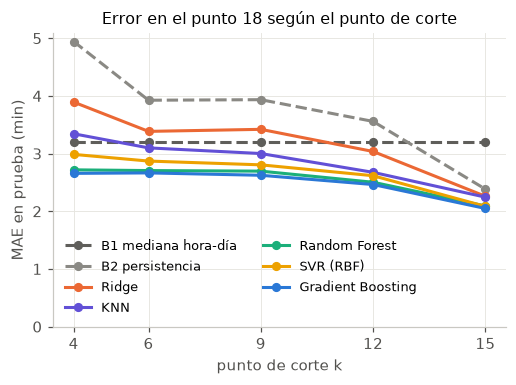

In [8]:
DESTACADOS = ["B1 mediana hora-día", "B2 persistencia", "Ridge", "KNN", "Random Forest", "SVR (RBF)", "Gradient Boosting"]
fig, ax = plt.subplots(figsize=(4.8, 3.6))
for nombre in DESTACADOS:
    d = todo[todo["modelo"] == nombre].sort_values("k")
    estilo_linea = "--" if nombre.startswith("B") else "-"
    ax.plot(d["k"], d["MAE"], marker="o", linestyle=estilo_linea, color=graficos.COLOR_MODELO[nombre], label=nombre)
ax.set(xlabel="punto de corte k", ylabel="MAE en prueba (min)", xticks=CORTES, ylim=(0, None),
       title="Error en el punto 18 según el punto de corte")
ax.legend(loc="lower left", ncol=2)
graficos.guardar(fig, DIR_FIG / "04_mae_vs_k.png")

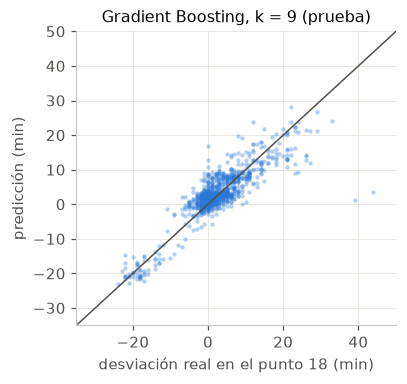

In [9]:
pred = pd.read_pickle(DIR_PROC / "04_pred_test.pkl")
mejor9 = mejor.loc[mejor["k"] == 9, "modelo"].item()
p9 = pred[(pred["k"] == 9) & (pred["modelo"] == mejor9)]
fig, ax = plt.subplots(figsize=(3.8, 3.6))
ax.scatter(p9["y"], p9["pred"], s=8, alpha=0.35, color=graficos.PALETA[0], linewidths=0)
lim = (-35, 50)
ax.plot(lim, lim, color=graficos.TEXTO_SEC, linewidth=1)
ax.set(xlim=lim, ylim=lim, xlabel="desviación real en el punto 18 (min)", ylabel="predicción (min)",
       title=f"{mejor9}, k = 9 (prueba)")
graficos.guardar(fig, DIR_FIG / "04_pred_vs_real_k9.png")

## 4. Error por franja horaria y día (k = 9)

In [10]:
todas = pd.concat([pd.read_pickle(DIR_PROC / "03_pred_test.pkl"), pred])
todas["error_abs"] = (todas["y"] - todas["pred"]).abs()
sel = todas[(todas["k"] == 9) & todas["modelo"].isin(DESTACADOS)]
por_franja = sel.pivot_table(index="franja", columns="modelo", values="error_abs", aggfunc="mean")[DESTACADOS]
por_franja.insert(0, "n", sel[sel["modelo"] == DESTACADOS[0]].groupby("franja").size())
por_franja.round(2).to_csv(DIR_TAB / "04_mae_por_franja_k9.csv")
por_franja.round(2)

modelo,n,B1 mediana hora-día,B2 persistencia,Ridge,KNN,Random Forest,SVR (RBF),Gradient Boosting
franja,,,,,,,,
04-07 h,181,3.89,4.25,2.99,2.06,2.03,2.20,1.96
07-10 h,215,2.38,2.85,2.96,2.57,2.29,2.37,2.34
10-13 h,219,2.40,3.15,3.15,2.95,2.24,2.36,2.10
13-16 h,220,3.18,3.75,3.24,2.99,2.97,2.86,2.92
16-19 h,190,4.39,5.91,4.21,4.10,3.74,3.88,3.59
19-22 h,36,3.36,4.39,6.89,4.93,4.05,5.17,3.85


In [11]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia = sel.pivot_table(index="dia_semana", columns="modelo", values="error_abs", aggfunc="mean")[DESTACADOS]
por_dia.index = [DIAS[i] for i in por_dia.index]
por_dia.round(2).to_csv(DIR_TAB / "04_mae_por_dia_k9.csv")
por_dia.round(2)

modelo,B1 mediana hora-día,B2 persistencia,Ridge,KNN,Random Forest,SVR (RBF),Gradient Boosting
lun,3.90,3.70,4.20,3.15,2.83,3.24,2.89
mar,2.50,3.22,2.65,2.27,2.30,2.17,2.16
mié,2.79,2.93,2.96,2.67,2.21,2.35,2.17
jue,2.30,3.04,3.00,2.41,2.11,2.36,2.08
vie,3.11,3.68,3.31,3.00,2.75,3.03,2.63
sáb,5.64,9.33,5.39,5.74,4.93,4.61,4.62
dom,3.01,3.48,2.99,2.60,2.50,2.36,2.52


## 5. Conclusiones
- Gradient Boosting tiene el menor MAE de validación en los cinco cortes (3,09 min en k = 4 a 2,38 en k = 15) y también el menor en prueba (2,66 a 2,05 min).
- En k = 9: MAE 2,62 min, mediana del error 1,95, RMSE 3,85, R² 0,75 y 86,8 % de vueltas con error ≤ 5 min. Es 18,0 % mejor que B1 y 33,3 % mejor que la persistencia.
- Random Forest, Bagging y SVR quedan cerca (2,70–2,81 en k = 9). Los lineales (Ridge, Lasso, Huber, lineal con GD) rondan 3,3–3,5 y no superan a B1. La selección de variables del notebook 02 se eligió con Gradient Boosting: a los ensambles no les cambia el error, pero los lineales pierden entre 0,1 y 0,15 min porque ya no ven la duración programada de cada tramo.
- La rejilla ampliada de Gradient Boosting (81 combinaciones) elige en k = 9 y 15 la tasa mínima (0,01) con el máximo de árboles (1.000): es el compromiso habitual entre tasa y número de árboles, y el MAE de validación apenas cambia (2,984 → 2,980 en k = 9), así que ampliar más la rejilla no aportaría.
- El error crece en la franja de 16 a 19 h y los sábados, donde se concentran los atrasos grandes.
- En k = 9 el MAE de prueba es menor que el de validación en todos los modelos: la semana de prueba es más fácil, el orden de los modelos se mantiene y las cifras absolutas de prueba deben leerse con esa cautela.

In [12]:
import platform, sklearn, scipy
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.14.2 | pandas 3.0.3 | numpy 2.5.0 | scikit-learn 1.9.0 | scipy 1.18.0
